<a href="https://colab.research.google.com/github/hsu01/emotion-detection/blob/main/notebooks/02_cnn_augmented.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSE 455: Facial Expression Recognition (Experiment B: CNN + Data Augmentation)

**Course:** CSE 455 Computer Vision, Autumn 2026

**Team:** Hsu Wai Hnin Kyaw, Larrianna Warner, Xuan Nhu Tran, Rina Yuan

**Project:** Facial Expression Recognition Using Deep Learning: Improving Robustness Under Real-World Conditions

## Goal
Experiment A trained a CNN on the FER2013 face pictures as they are. In this notebook we train the **exact same CNN**, but we randomly change the training pictures a little each time the model sees them. We flip them, tilt them, make them brighter or darker, and sometimes cover a small part of the face.

The idea is that real photos aren't as clean as FER2013. People tilt their heads, the lighting is bad, or something is covering part of their face. If the model practices on pictures like that, it should handle them better. This is called **data augmentation**.

## The 2x2 experiment design
| Experiment | Model | Augmentation |
|---|---|---|
| A | CNN trained from scratch | No |
| **B (this notebook)** | CNN trained from scratch | **Yes** |
| C | Pretrained ResNet18 | No |
| D | Pretrained ResNet18 | Yes |

Everything else is the same as Experiment A: same model, same train/validation split, same seed, same learning rate, same number of epochs. That way, if the results change, we know it's because of the augmentation and not something else.

## How to run
**On Colab:**
1. Runtime → Change runtime type → **T4 GPU**.
2. Add your Kaggle info in Colab Secrets (section 1), same as in Experiment A.
3. Run all the cells from top to bottom. Results get saved to `MyDrive/emotion-detection/checkpoints/B_augmented/` in your Google Drive.

**On your own computer:** this also works locally (that's how the outputs saved in this notebook were made, on a Mac).
1. Install the packages: `pip install -r requirements.txt`
2. Unzip the FER2013 download from Kaggle into `data/fer2013/` in the repo, so you have `data/fer2013/train/` and `data/fer2013/test/`.
3. Run all the cells. The notebook notices it's not on Colab, skips the Kaggle and Drive steps, uses your GPU if it has one (Apple Silicon works), and saves results to `results/B_augmented/`.

## 0. Setup

In [1]:
import sys

# Are we on Colab or on our own computer? A few cells below act differently depending on this.
IN_COLAB = 'google.colab' in sys.modules
print('Running in Colab:', IN_COLAB)

# Install dependencies (torch/torchvision are already on Colab, but this makes the notebook self-contained).
# On your own computer, install from requirements.txt instead.
if IN_COLAB:
    !pip install -q torch torchvision scikit-learn matplotlib seaborn pandas

Running in Colab: False


In [2]:
import torch

print('PyTorch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    print('GPU: Apple Silicon (MPS)')
    device = torch.device('mps')
else:
    print('WARNING: no GPU found. On Colab, switch to a GPU runtime (Runtime -> Change runtime type -> T4).')
    device = torch.device('cpu')

print('Using device:', device)

PyTorch version: 2.8.0
CUDA available: False
GPU: Apple Silicon (MPS)
Using device: mps


## 1. Get the data: FER2013 from Kaggle

This is the same dataset as Experiment A ([msambare/fer2013](https://www.kaggle.com/datasets/msambare/fer2013)). It has about 35,887 grayscale face pictures, each 48x48 pixels, split into `train/` and `test/` folders with one subfolder per emotion. **We don't touch the test set in this notebook.** It's saved for the final evaluation. For validation we use part of the train set (section 3).

**Before you run the next cell, set up your Kaggle info (pick one):**
- **Option A (easiest):** in Colab, click the key icon on the left (Secrets) and add two secrets: `KAGGLE_USERNAME` (your Kaggle username) and `KAGGLE_KEY` (your API key).
- **Option B:** on Kaggle, go to your profile → Settings → **Create New API Token**. This downloads `kaggle.json`. Upload it in the Files panel in Colab, then run `!cp kaggle.json ~/.kaggle/kaggle.json`.

Don't commit `kaggle.json` to GitHub. It's already in the `.gitignore`.

In [3]:
import json
import os

if not IN_COLAB:
    print('Not on Colab, so skipping the Kaggle download. Using the local copy in data/fer2013/ instead.')
else:
    # --- Kaggle credentials (see the cell above) ---
    os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)

    try:
        from google.colab import userdata
        creds = {'username': userdata.get('KAGGLE_USERNAME'), 'key': userdata.get('KAGGLE_KEY')}
        with open(os.path.expanduser('~/.kaggle/kaggle.json'), 'w') as f:
            json.dump(creds, f)
        print('Kaggle credentials written from Colab Secrets.')
    except Exception as e:
        print('Colab Secrets not found. Upload kaggle.json and copy it to ~/.kaggle/ :', e)

    if not os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
        raise RuntimeError('kaggle.json not found. Add KAGGLE_USERNAME / KAGGLE_KEY as Colab Secrets, '
                           'or upload kaggle.json and run: !cp kaggle.json ~/.kaggle/kaggle.json')
    os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)

    # --- Download FER2013 (msambare/fer2013) ---
    # The zip has train/ and test/ folders, each with 7 emotion subfolders.
    !mkdir -p /content/data
    !kaggle datasets download -d msambare/fer2013 -p /content/data --unzip
    !ls /content/data
    print('Download finished.')

Not on Colab, so skipping the Kaggle download. Using the local copy in data/fer2013/ instead.


In [4]:
from collections import Counter
from pathlib import Path

# On Colab the data is downloaded to /content/data.
# On your own computer, unzip FER2013 into data/fer2013/ in the repo (this notebook runs from notebooks/).
DATA_ROOT = '/content/data' if IN_COLAB else '../data/fer2013'

train_dir = Path(DATA_ROOT) / 'train'
test_dir = Path(DATA_ROOT) / 'test'
assert train_dir.is_dir(), f'train/ not found under {DATA_ROOT}. Check DATA_ROOT.'
assert test_dir.is_dir(), f'test/ not found under {DATA_ROOT}. Check DATA_ROOT.'

# Class names in alphabetical order. This is also the label order ImageFolder uses
# (0=angry, 1=disgust, 2=fear, 3=happy, 4=neutral, 5=sad, 6=surprise).
CLASS_NAMES = sorted(d.name for d in train_dir.iterdir() if d.is_dir())
print('Classes:', CLASS_NAMES)

for split, d in [('train', train_dir), ('test', test_dir)]:
    counts = {cls: len([p for p in (d / cls).iterdir() if p.is_file()]) for cls in CLASS_NAMES}
    total = sum(counts.values())
    print(f'\n{split}: {total} images')
    for cls in CLASS_NAMES:
        print(f'  {cls:9s} {counts[cls]:5d}  ({counts[cls] / total:.1%})')

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

train: 28709 images
  angry      3995  (13.9%)
  disgust     436  (1.5%)
  fear       4097  (14.3%)
  happy      7215  (25.1%)
  neutral    4965  (17.3%)
  sad        4830  (16.8%)
  surprise   3171  (11.0%)

test: 7178 images
  angry       958  (13.3%)
  disgust     111  (1.5%)
  fear       1024  (14.3%)
  happy      1774  (24.7%)
  neutral    1233  (17.2%)
  sad        1247  (17.4%)
  surprise    831  (11.6%)


## 2. Explore the data

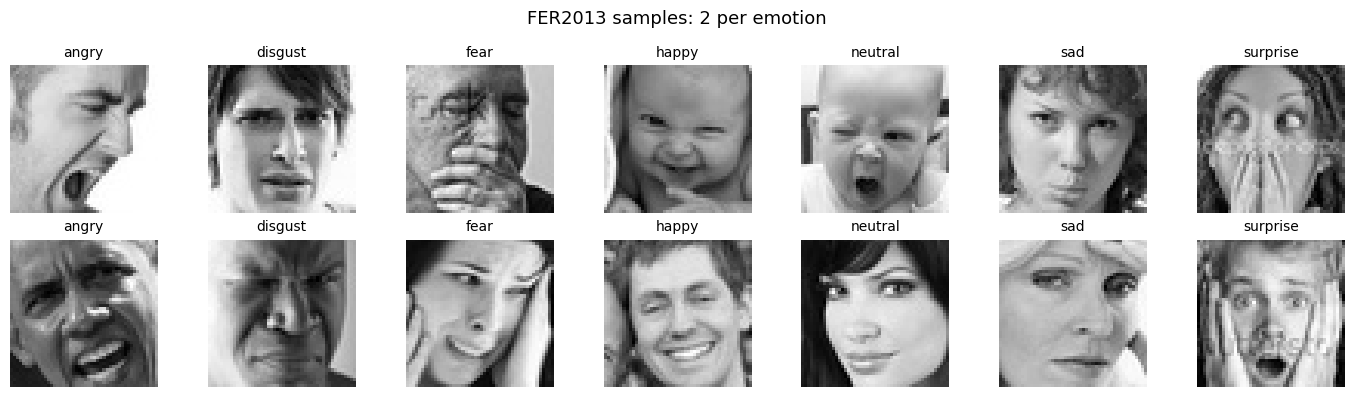

In [5]:
import random

import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

fig, axes = plt.subplots(2, 7, figsize=(14, 4))
for j, cls in enumerate(CLASS_NAMES):
    imgs = list((train_dir / cls).iterdir())
    chosen = random.sample(imgs, 2)
    for i, path in enumerate(chosen):
        axes[i, j].imshow(Image.open(path), cmap='gray')
        axes[i, j].set_title(cls, fontsize=10)
        axes[i, j].axis('off')
plt.suptitle('FER2013 samples: 2 per emotion', fontsize=13)
plt.tight_layout()
plt.show()

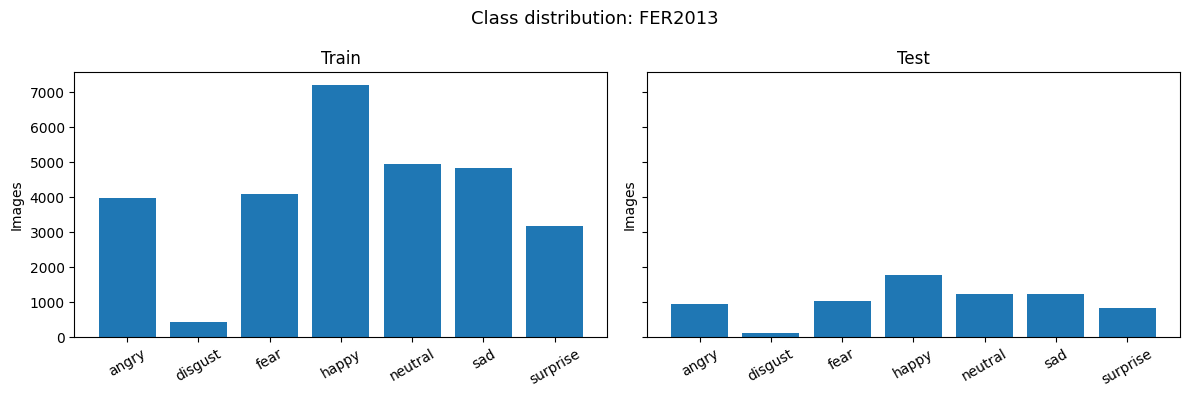

Train counts: {'angry': 3995, 'disgust': 436, 'fear': 4097, 'happy': 7215, 'neutral': 4965, 'sad': 4830, 'surprise': 3171}


In [6]:
import matplotlib.pyplot as plt

train_counts = {cls: len([p for p in (train_dir / cls).iterdir() if p.is_file()]) for cls in CLASS_NAMES}
test_counts = {cls: len([p for p in (test_dir / cls).iterdir() if p.is_file()]) for cls in CLASS_NAMES}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, counts, title in [(axes[0], train_counts, 'Train'), (axes[1], test_counts, 'Test')]:
    ax.bar(counts.keys(), counts.values())
    ax.set_title(title)
    ax.set_ylabel('Images')
    ax.tick_params(axis='x', rotation=30)
plt.suptitle('Class distribution: FER2013', fontsize=13)
plt.tight_layout()
plt.show()

print('Train counts:', train_counts)

### What to notice: class imbalance
Some emotions have way more pictures than others. **Disgust only has a few hundred**, while **happy has several thousand**. So the model sees a lot of happy faces and barely any disgust faces, and it's going to be much worse at disgust. That's why in section 6 we look at the score for each emotion and the confusion matrix, not just the overall accuracy.

## 3. Preprocessing, augmentation, and train/validation split

**This is the only section that's different from Experiment A.**

- **Train/validation split:** same as Experiment A. We take the official train set and split it 90% train / 10% validation (seed 42). The split is "stratified", which just means each emotion keeps the same share in both parts.
- **Validation and test pictures:** same as Experiment A, with **no augmentation**. We want to grade the model on normal, unchanged pictures.
- **Training pictures:** these get augmented. Every time the model sees a training picture, it gets a slightly different random version of it.

### The augmentations
Each one goes with a real-world problem from our research question:

| Augmentation | What it does | Real-world problem it copies |
|---|---|---|
| `RandomHorizontalFlip()` | flips the face left/right half the time | faces can point either way |
| `RandomRotation(15)` | tilts the face up to 15° either way | people tilt their heads |
| `ColorJitter(brightness=0.4)` | makes it anywhere from 60% to 140% as bright | bad lighting (too dark or too bright) |
| `RandomErasing(p=0.25, scale=(0.02, 0.15))` | 1 in 4 pictures gets a small gray box over part of the face | something covering the face (hand, glasses, mask) |

We kept these **a little weaker than the robustness tests** we'll run later (those use 30° tilts and 50% / 150% brightness). If we trained on the exact same changes we test on, the test wouldn't really show if the model learned to handle new situations.

`RandomErasing` goes at the end because it only works on tensors (after `ToTensor`), not on regular images.

**Note for Experiment D:** use these same augmentations so B and D can be compared fairly.

In [7]:
import random

import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Experiment B: augmentation on the TRAINING pictures only.
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.RandomHorizontalFlip(),                      # flip left/right
    transforms.RandomRotation(15),                          # tilt up to 15 degrees
    transforms.ColorJitter(brightness=0.4),                 # brighter or darker
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),   # cover a small patch
])

# Validation/test: exactly the same as Experiment A (no augmentation).
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

train_ds = datasets.ImageFolder(train_dir, transform=train_transform)
val_ds = datasets.ImageFolder(train_dir, transform=eval_transform)  # same images, no augmentation
test_ds = datasets.ImageFolder(test_dir, transform=eval_transform)
print('Classes (index order):', train_ds.classes)

# Stratified 90/10 split of the OFFICIAL train set (seed 42). Same split as Experiment A.
# The official test set stays untouched.
targets = train_ds.targets
train_idx, val_idx = train_test_split(
    range(len(train_ds)), test_size=0.10, random_state=42, stratify=targets
)
train_subset = Subset(train_ds, train_idx)
val_subset = Subset(val_ds, val_idx)
print(f'Train: {len(train_subset)} | Val: {len(val_subset)} | Test (held out): {len(test_ds)}')

BATCH_SIZE = 64
# Colab: 2 background workers load pictures faster. On a Mac, loading in the main process (0) is simplest.
NUM_WORKERS = 2 if IN_COLAB else 0
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

images, labels = next(iter(train_loader))
print('Batch:', images.shape, labels.shape)  # expect torch.Size([64, 1, 48, 48]) torch.Size([64])

Classes (index order): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Train: 25838 | Val: 2871 | Test (held out): 7178
Batch: torch.Size([64, 1, 48, 48]) torch.Size([64])


### Check: what the augmented pictures look like
Each row is one training picture. The first one is the original, and the next 5 are random augmented versions of it. You should still be able to tell it's a face and what the emotion is. If you can't, the augmentation is too strong.

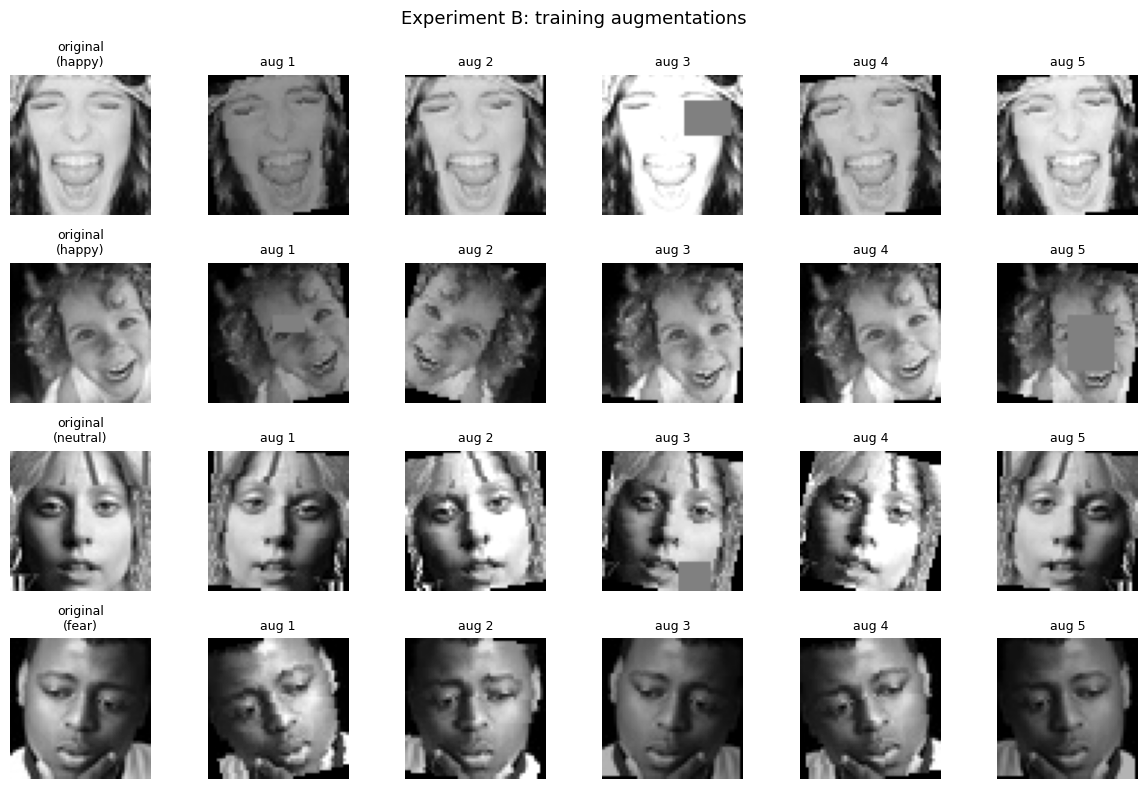

In [8]:
import matplotlib.pyplot as plt

def to_img(t):
    return (t.squeeze(0) * 0.5 + 0.5).clamp(0, 1).numpy()  # undo Normalize so it displays right

rng = random.Random(0)
sample_idx = rng.sample(list(train_idx), 4)
n_aug = 5
fig, axes = plt.subplots(len(sample_idx), n_aug + 1, figsize=(2 * (n_aug + 1), 2 * len(sample_idx)))
for r, idx in enumerate(sample_idx):
    path, label = train_ds.samples[idx]
    axes[r, 0].imshow(to_img(val_ds[idx][0]), cmap='gray', vmin=0, vmax=1)
    axes[r, 0].set_title(f'original\n({CLASS_NAMES[label]})', fontsize=9)
    for c in range(1, n_aug + 1):
        axes[r, c].imshow(to_img(train_ds[idx][0]), cmap='gray', vmin=0, vmax=1)
        axes[r, c].set_title(f'aug {c}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('Experiment B: training augmentations', fontsize=13)
plt.tight_layout()
plt.show()

## 4. Model: baseline CNN (same as Experiment A)

This is the exact same model as Experiment A. Nothing changed here.

It's a CNN with 3 convolutional blocks for 48x48 grayscale pictures and 7 outputs (one per emotion). Each block is Conv → BatchNorm → ReLU → MaxPool, and each one cuts the picture size in half:

- Block 1: 48x48 to 24x24 (32 channels)
- Block 2: 24x24 to 12x12 (64 channels)
- Block 3: 12x12 to 6x6 (128 channels)

Then it flattens to `128 * 6 * 6 = 4608` numbers and goes through two fully-connected layers (4608 to 256 to 7), with dropout 0.5 before the last layer.

In [9]:
import torch.nn as nn


class BaselineCNN(nn.Module):
    """3-block CNN for 48x48 grayscale faces -> 7 emotions.

    48x48 --pool--> 24x24 --pool--> 12x12 --pool--> 6x6,
    then flatten 128*6*6 = 4608.
    """

    def __init__(self, num_classes=7, dropout_p=0.5):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 48x48 -> 24x24
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            # Block 2: 24x24 -> 12x12
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            # Block 3: 12x12 -> 6x6
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 6 * 6, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = BaselineCNN(num_classes=len(CLASS_NAMES)).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'Trainable parameters: {n_params:,}')

# Shape check: a batch of 2 grayscale 48x48 images should come out as (2, 7).
with torch.no_grad():
    out = model(torch.randn(2, 1, 48, 48).to(device))
print('Output shape:', tuple(out.shape))
assert tuple(out.shape) == (2, len(CLASS_NAMES))

Trainable parameters: 1,274,823
Output shape: (2, 7)


## 5. Training

Same settings as Experiment A: Adam (learning rate 0.001), CrossEntropyLoss, 15 epochs, batch size 64. After every epoch, if the validation accuracy is the best so far, we save the model (the "checkpoint").

On a Colab T4 GPU this should take around 10 to 20 minutes. It might be a little slower than Experiment A because changing the pictures takes extra work.

**Heads up:** the training accuracy will probably be *lower* than the validation accuracy. That's normal here. The training pictures are the harder, changed ones, and the validation pictures are the normal ones.

In [10]:
import os

if IN_COLAB:
    # Save to Google Drive so the results don't disappear when the Colab session ends.
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = '/content/drive/MyDrive/emotion-detection/checkpoints/B_augmented'
    A_DIR = '/content/drive/MyDrive/emotion-detection/checkpoints/A_baseline'
else:
    # On your own computer, save to results/ in the repo (it's in .gitignore, so it won't get committed).
    CHECKPOINT_DIR = '../results/B_augmented'
    A_DIR = '../results/A_baseline'

RESULTS_DIR = CHECKPOINT_DIR
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print('Saving checkpoints and results to:', CHECKPOINT_DIR)

Saving checkpoints and results to: ../results/B_augmented


In [11]:
import json
import time

import torch.nn as nn
from tqdm import tqdm

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
NUM_EPOCHS = 15
best_path = os.path.join(CHECKPOINT_DIR, 'best_cnn_augmented.pth')


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, desc='train', leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, desc='val', leave=False):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        running_loss += criterion(outputs, labels).item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0

print(f'Training for {NUM_EPOCHS} epochs (Adam lr=0.001, batch={BATCH_SIZE}, with augmentation)...')
for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate_loss_acc(model, val_loader, criterion, device)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                    'val_acc': best_val_acc}, best_path)
    print(f'Epoch {epoch:2d}/{NUM_EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.4f} | '
          f'val loss {val_loss:.4f} acc {val_acc:.4f} | {time.time() - t0:.0f}s')

with open(os.path.join(CHECKPOINT_DIR, 'history_cnn_augmented.json'), 'w') as f:
    json.dump(history, f, indent=2)
print(f'\nBest val accuracy: {best_val_acc:.4f}. Checkpoint saved to {best_path}')

Training for 15 epochs (Adam lr=0.001, batch=64, with augmentation)...



train:   0%|          | 0/404 [00:00<?, ?it/s]


train:   0%|          | 1/404 [00:00<01:54,  3.51it/s]


train:   1%|          | 5/404 [00:00<00:26, 14.82it/s]


train:   2%|▏         | 9/404 [00:00<00:17, 22.23it/s]


train:   3%|▎         | 13/404 [00:00<00:14, 26.11it/s]

... (1,214 outputs left out)


val:  31%|███       | 14/45 [00:00<00:00, 131.27it/s]


val:  62%|██████▏   | 28/45 [00:00<00:00, 132.03it/s]


val:  93%|█████████▎| 42/45 [00:00<00:00, 132.37it/s]

Epoch 15/15 | train loss 1.3591 acc 0.4735 | val loss 1.2038 acc 0.5517 | 7s

Best val accuracy: 0.5517. Checkpoint saved to ../results/B_augmented/best_cnn_augmented.pth


## 6. Evaluation

Now we load the best checkpoint and test it on the validation set (still not the test set). We look at:
- **precision / recall / F1 for each emotion**, because overall accuracy hides how bad the model is at the rare emotions
- **the confusion matrix**, to see which emotions get mixed up
- **the training curves**, to see how training went over the epochs

All of these get saved to the `B_augmented` folder in Drive.

In [12]:
checkpoint = torch.load(best_path, map_location=device, weights_only=True)

# Load only the model weights
model.load_state_dict(checkpoint['model_state_dict'])

# Set model to evaluation mode
model.eval()

print('Best augmented CNN loaded successfully!')
print('Best epoch:', checkpoint['epoch'])
print('Validation accuracy:', checkpoint['val_acc'])

Best augmented CNN loaded successfully!
Best epoch: 15
Validation accuracy: 0.5517241379310345


In [13]:
from sklearn.metrics import classification_report

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in tqdm(val_loader, desc='eval'):
        outputs = model(images.to(device))
        all_preds.extend(outputs.argmax(1).cpu().tolist())
        all_labels.extend(labels.tolist())

print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES, digits=4, zero_division=0))

# Save the report as JSON
report = classification_report(all_labels, all_preds, target_names=CLASS_NAMES,
                               output_dict=True, zero_division=0)
report_path = os.path.join(RESULTS_DIR, 'classification_report.json')
with open(report_path, 'w') as f:
    json.dump(report, f, indent=4)
print('Classification report saved to:', report_path)


eval:   0%|          | 0/45 [00:00<?, ?it/s]


eval:  33%|███▎      | 15/45 [00:00<00:00, 142.55it/s]


eval:  67%|██████▋   | 30/45 [00:00<00:00, 141.89it/s]


eval: 100%|██████████| 45/45 [00:00<00:00, 142.38it/s]


eval: 100%|██████████| 45/45 [00:00<00:00, 142.15it/s]

              precision    recall  f1-score   support

       angry     0.5045    0.4211    0.4590       399
     disgust     0.0000    0.0000    0.0000        44
        fear     0.3540    0.1390    0.1996       410
       happy     0.7434    0.8546    0.7951       722
     neutral     0.5513    0.4980    0.5233       496
         sad     0.3544    0.6046    0.4468       483
    surprise     0.7382    0.6404    0.6858       317

    accuracy                         0.5517      2871
   macro avg     0.4637    0.4511    0.4442      2871
weighted avg     0.5440    0.5517    0.5336      2871

Classification report saved to: ../results/B_augmented/classification_report.json


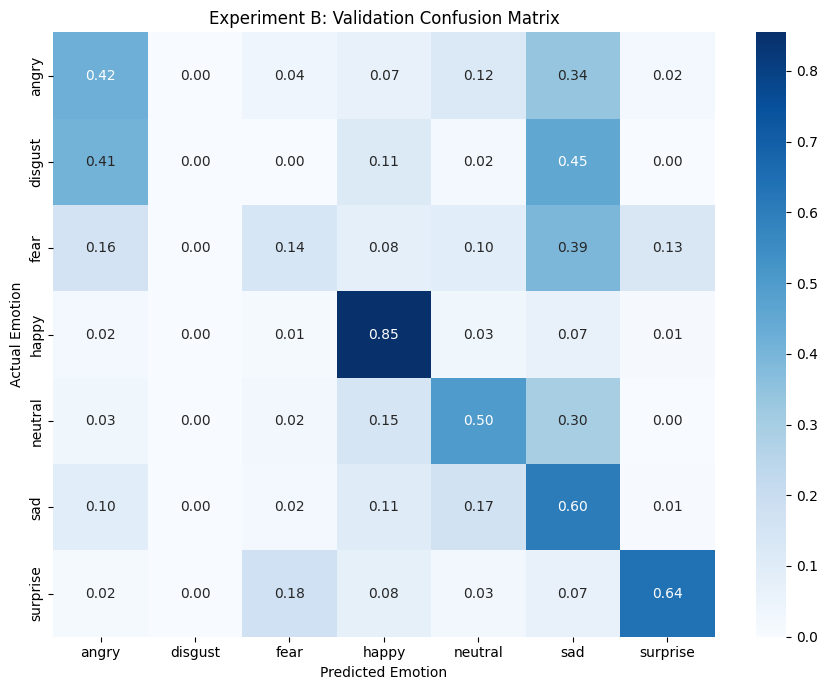

Confusion matrix saved to: ../results/B_augmented/confusion_matrix.png


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds, normalize='true')
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Experiment B: Validation Confusion Matrix')
plt.xlabel('Predicted Emotion')
plt.ylabel('Actual Emotion')
plt.tight_layout()
save_path = os.path.join(RESULTS_DIR, 'confusion_matrix.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()
print('Confusion matrix saved to:', save_path)

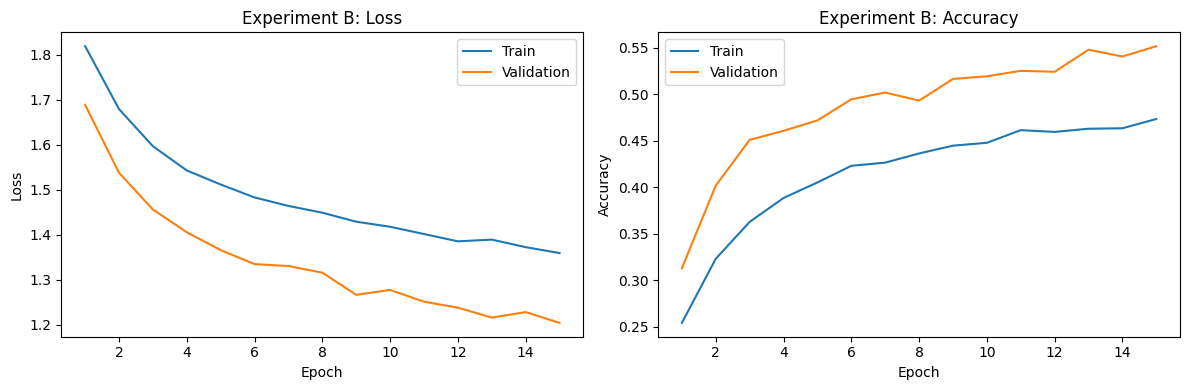

Training curves saved to: ../results/B_augmented/training_curves.png


In [15]:
epochs = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss graph
axes[0].plot(epochs, history['train_loss'], label='Train')
axes[0].plot(epochs, history['val_loss'], label='Validation')
axes[0].set_title('Experiment B: Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy graph
axes[1].plot(epochs, history['train_acc'], label='Train')
axes[1].plot(epochs, history['val_acc'], label='Validation')
axes[1].set_title('Experiment B: Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
save_path = os.path.join(RESULTS_DIR, 'training_curves.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()
print('Training curves saved to:', save_path)

## 7. Compare with Experiment A

This puts Experiment A and Experiment B side by side. It looks for your Experiment A results in `checkpoints/A_baseline/` in Drive (or `results/A_baseline/` when running locally), which come from running `01_baseline_cnn.ipynb`. If it can't find them, it uses the Experiment A numbers from the README instead.

The `change` column is B minus A, so positive means augmentation helped and negative means it got worse.

In [16]:
import pandas as pd

a_report_path = os.path.join(A_DIR, 'classification_report.json')

if os.path.exists(a_report_path):
    with open(a_report_path) as f:
        a_report = json.load(f)
    a_source = a_report_path
else:
    # Backup: Experiment A validation results from the README (team run, Nov 10).
    a_f1 = {'angry': 0.4596, 'disgust': 0.0, 'fear': 0.3107, 'happy': 0.7891,
            'neutral': 0.5554, 'sad': 0.4542, 'surprise': 0.6822}
    a_report = {cls: {'f1-score': a_f1[cls]} for cls in CLASS_NAMES}
    a_report['accuracy'] = 0.5629
    a_report['macro avg'] = {'f1-score': 0.4645}
    a_source = 'README (team run, Nov 10)'
print('Experiment A results from:', a_source)

rows = [('accuracy', a_report['accuracy'], report['accuracy']),
        ('macro F1', a_report['macro avg']['f1-score'], report['macro avg']['f1-score'])]
rows += [(f'F1 {cls}', a_report[cls]['f1-score'], report[cls]['f1-score']) for cls in CLASS_NAMES]
comparison = pd.DataFrame(rows, columns=['metric', 'A (no aug)', 'B (aug)'])
comparison['change'] = comparison['B (aug)'] - comparison['A (no aug)']
comparison.to_csv(os.path.join(RESULTS_DIR, 'comparison_vs_A.csv'), index=False)
comparison.style.format({'A (no aug)': '{:.4f}', 'B (aug)': '{:.4f}', 'change': '{:+.4f}'})

Experiment A results from: README (team run, Nov 10)


,metric,A (no aug),B (aug),change
0,accuracy,0.5629,0.5517,-0.0112
1,macro F1,0.4645,0.4442,-0.0203
2,F1 angry,0.4596,0.4590,-0.0006
3,F1 disgust,0.0000,0.0000,+0.0000
4,F1 fear,0.3107,0.1996,-0.1111
5,F1 happy,0.7891,0.7951,+0.0060
6,F1 neutral,0.5554,0.5233,-0.0321
7,F1 sad,0.4542,0.4468,-0.0074
8,F1 surprise,0.6822,0.6858,+0.0036


In [17]:
# List everything that got saved
for filename in sorted(os.listdir(RESULTS_DIR)):
    path = os.path.join(RESULTS_DIR, filename)
    print(f'{filename} ({os.path.getsize(path) / 1024:.1f} KB)')

best_cnn_augmented.pth (4990.3 KB)
classification_report.json (1.5 KB)
comparison_vs_A.csv (0.5 KB)
confusion_matrix.png (216.8 KB)
history_cnn_augmented.json (1.5 KB)
training_curves.png (169.1 KB)


## What I found

*I ran this on my Mac (Apple GPU) instead of Colab, using the same data, split, and settings. If you rerun it in Colab, the numbers might come out a tiny bit different.*

### Overall
| | Experiment A (no augmentation) | Experiment B (augmentation) |
|---|---:|---:|
| Best validation accuracy | 56.29% | **55.17%** |
| Macro F1 | 46.45% | **44.42%** |
| Best epoch | 14 | **15** (the last one) |
| Final training accuracy | 57.88% | **47.35%** |

So B came out about 1 point lower than A. But I don't think that means augmentation failed. It just didn't have enough time to finish learning (see below).

### Each emotion (F1 score)
| Emotion | A | B | Change |
|---|---:|---:|---:|
| Angry | 0.460 | 0.459 | about the same |
| Disgust | 0.000 | 0.000 | still 0 |
| Fear | 0.311 | 0.200 | worse |
| Happy | 0.789 | 0.795 | about the same |
| Neutral | 0.555 | 0.523 | a little worse |
| Sad | 0.454 | 0.447 | about the same |
| Surprise | 0.682 | 0.686 | about the same |

Augmentation didn't help the weak emotions. Disgust is still never predicted, and fear actually got worse.

### Training curves
- **No more overfitting.** In Experiment A, the validation loss started going back up near the end. In B, the validation loss keeps going down the whole time.
- **Training accuracy stayed below validation accuracy** (47% vs 55%). That's expected because the training pictures are the harder, changed ones.
- **It was still improving at epoch 15.** The best epoch was the last one, so the model probably needed more epochs.

### Confusion matrix
The biggest problem is that the model guesses **"sad" way too often**:
- 39% of fear faces got predicted as sad (only 14% were predicted correctly as fear)
- 45% of disgust faces got predicted as sad, and 41% as angry
- 34% of angry faces and 30% of neutral faces got predicted as sad
- 18% of surprise faces got predicted as fear

That's why sad has a high recall (0.60) but a low precision (0.35). It catches most of the sad faces, but a lot of what it calls "sad" isn't actually sad.

### Takeaway
With the same 15 epochs as Experiment A, augmentation stopped the overfitting but didn't improve accuracy on normal pictures (55.2% vs 56.3%), because the model hadn't finished learning yet. The real test is the robustness evaluation, where we check how the models do on dark, bright, tilted, and covered faces.

## Notes for the next experiments
- **D (ResNet18 + augmentation):** use the same augmentations from section 3, so the comparison between B and D is fair.
- **Robustness tests:** test every model on the same changed versions of the *test* set: dark (brightness x0.5), bright (x1.5), tilted (±15° / ±30°), eyes covered, mouth covered.
- The checkpoint and figures are in `results/B_augmented/` (or the `B_augmented` folder in Drive). Don't upload those to GitHub. Share them through the team Drive.